# Stage 6 - Biological interpretation (Task 7)
**Author:** Myra Akinyi Nyamwanda  |  **Project:** Comparative analysis of genetic conservation and variation in selected SARS-CoV-2 genes

Stage 5 measured *how much* each gene varies. This notebook asks *where* inside each protein the variation falls, and whether that matches what the literature reports.

| Step | What it produces |
|---|---|
| 6.1 | Protein domain coordinates for S, E, M, N and RdRp, and the number of changes per 100 residues in each |
| 6.2 | Figure 7a: the Spike domain map with the changes each variant carries |
| 6.3 | Figure 7b: Nucleocapsid, split into structured domains and disordered regions |
| 6.4 | Figure 7c/7d: the RdRp catalytic motifs and the non-synonymous to synonymous ratio |
| 6.5 | A comparison table of every finding against the published source it agrees or disagrees with |

**Inputs** (written by Stage 5): `results/stage5_codon_changes_per_genome.csv`, `results/stage5_gene_conservation.csv`, `results/stage5_known_mutations.csv`.
**Outputs**: `results/stage6_domain_density.csv`, `stage6_rdrp_catalytic_check.csv`, `stage6_literature_comparison.csv`, and figures `fig7a`-`fig7d`.

In [1]:
from pathlib import Path
import os, subprocess
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    colab_root = Path("/content/bioinformatics-group-project")
    if not colab_root.exists():
        subprocess.run(["git","clone","https://github.com/JudahNdivo/bioinformatics-group-project.git",
                        str(colab_root)], check=True)
    os.chdir(colab_root)

cwd = Path.cwd()
PROJECT_ROOT = cwd if (cwd/"data").is_dir() else cwd.parent
RES_DIR = PROJECT_ROOT/"results"; FIG_DIR = RES_DIR/"figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

needed = ["stage5_codon_changes_per_genome.csv","stage5_gene_conservation.csv","stage5_known_mutations.csv"]
missing = [f for f in needed if not (RES_DIR/f).exists()]
if missing:
    raise FileNotFoundError(f"Missing Stage 5 outputs {missing}. Run 03_core_analysis.ipynb first.")

import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi":110,"savefig.dpi":200})

VARIANTS = ["Alpha","Beta","Delta","Omicron"]
changes = pd.read_csv(RES_DIR/"stage5_codon_changes_per_genome.csv")
cons    = pd.read_csv(RES_DIR/"stage5_gene_conservation.csv")
known   = pd.read_csv(RES_DIR/"stage5_known_mutations.csv")
N_SEL   = changes.groupby("variant").strain.nunique().reindex(VARIANTS).to_dict()
print("Genomes per variant:", N_SEL)
print(f"{len(changes):,} codon-level changes across {changes.strain.nunique()} genomes")

Genomes per variant: {'Alpha': 25, 'Beta': 4, 'Delta': 25, 'Omicron': 25}
2,418 codon-level changes across 79 genomes


### 6.1 Protein domains and change density
A change is counted once per **distinct amino-acid label** (for example `N501Y`), not once per genome, so a change fixed in a whole variant counts the same as one seen in a single genome. Density is distinct changes per 100 residues, which allows domains of very different sizes to be compared.

Domain boundaries follow the standard Wuhan-Hu-1 numbering used in the structural literature: Spike NTD 14-305 and RBD 319-541 with the receptor-binding motif (RBM) at 437-508; the S1/S2 cleavage region around 681-685; the fusion peptide at 816-833. Nucleocapsid is split into its two folded domains (RNA-binding 44-180, dimerisation 248-365) and the three disordered regions between and around them. RdRp is divided into the NiRAN, interface, fingers, palm and thumb subdomains, with the catalytic motifs A, B and C inside the palm.

In [2]:
DOMAINS = {
 "S":[("Signal peptide",1,13),("NTD",14,305),("NTD-RBD linker",306,318),("RBD",319,541),
      ("SD1",542,591),("SD2 / cleavage region",592,685),("Fusion peptide",816,833),
      ("HR1",910,985),("Central helix",986,1035),("Connector domain",1076,1141),
      ("HR2",1163,1213),("Transmembrane",1214,1237),("Cytoplasmic tail",1238,1273)],
 "N":[("N-terminal IDR",1,43),("RNA-binding domain",44,180),("SR-rich linker",181,247),
      ("Dimerisation domain",248,365),("C-terminal IDR",366,419)],
 "M":[("N-terminal ectodomain",1,19),("Transmembrane 1",20,38),("Transmembrane 2",50,72),
      ("Transmembrane 3",78,99),("C-terminal endodomain",100,222)],
 "E":[("N-terminal",1,8),("Transmembrane / viroporin",9,38),("C-terminal",39,75)],
 "RdRp":[("NiRAN",4,250),("Interface",251,365),("Fingers",366,581),("Palm (motif A)",582,620),
         ("Fingers (cont.)",621,679),("Palm (motif B)",680,710),("Palm (motif C)",711,815),
         ("Thumb",816,920)],
}
RBM = (437,508)

def carrier_pct(gene):
    sub = changes[changes.gene==gene]
    piv = (sub.groupby(["codon","label","variant"]).strain.nunique()
              .unstack(fill_value=0).reindex(columns=VARIANTS, fill_value=0))
    return (piv/pd.Series(N_SEL)*100).round(0).reset_index()

PCT = {g: carrier_pct(g) for g in DOMAINS}

rows=[]
for g, doms in DOMAINS.items():
    for name,a,b in doms:
        d = PCT[g][PCT[g].codon.between(a,b)]
        rows.append({"gene":g,"domain":name,"start":a,"end":b,"residues":b-a+1,
                     "distinct_changes":len(d),
                     "changes_per_100_aa":round(len(d)/(b-a+1)*100,2)})
rbm = PCT["S"][PCT["S"].codon.between(*RBM)]
rows.append({"gene":"S","domain":"RBM (inside RBD)","start":RBM[0],"end":RBM[1],
             "residues":RBM[1]-RBM[0]+1,"distinct_changes":len(rbm),
             "changes_per_100_aa":round(len(rbm)/(RBM[1]-RBM[0]+1)*100,2)})
density = pd.DataFrame(rows)
density.to_csv(RES_DIR/"stage6_domain_density.csv", index=False)

print("Spike, ranked by change density:")
print(density[density.gene=="S"].sort_values("changes_per_100_aa",ascending=False)
        [["domain","residues","distinct_changes","changes_per_100_aa"]].to_string(index=False))

Spike, ranked by change density:
               domain  residues  distinct_changes  changes_per_100_aa
     RBM (inside RBD)        72                39               54.17
                  RBD       223                58               26.01
                  NTD       292                54               18.49
SD2 / cleavage region        94                14               14.89
                  HR1        76                10               13.16
                  SD1        50                 6               12.00
     Cytoplasmic tail        36                 4               11.11
     Connector domain        66                 6                9.09
                  HR2        51                 4                7.84
       Signal peptide        13                 1                7.69
        Transmembrane        24                 1                4.17
        Central helix        50                 1                2.00
       NTD-RBD linker        13                 0        

**Interpretation 6.1:**
Spike is not uniformly variable. The receptor-binding motif, the 72 residues that actually touch ACE2, carries 54.2 changes per 100 residues, twice the density of the whole RBD (26.0) and three times that of the NTD (18.5). At the other end, the fusion peptide (816-833) and the NTD-RBD linker (306-318) carry **no changes at all** in any of the 79 genomes, and the central helix carries one synonymous change. The parts of Spike that perform the mechanical work of membrane fusion are therefore invariant in this sample, while the surface that antibodies bind is the most variable part of the whole study. This is the pattern expected if antibody pressure, rather than a general tendency of Spike to mutate, drives its variation.

### 6.2 Figure 7a: the Spike domain map
Each dot is an amino-acid change carried by at least 50% of the genomes of that variant; dot size is the carrier percentage. Shaded bands mark the NTD, the RBD, the RBM and the fusion peptide.

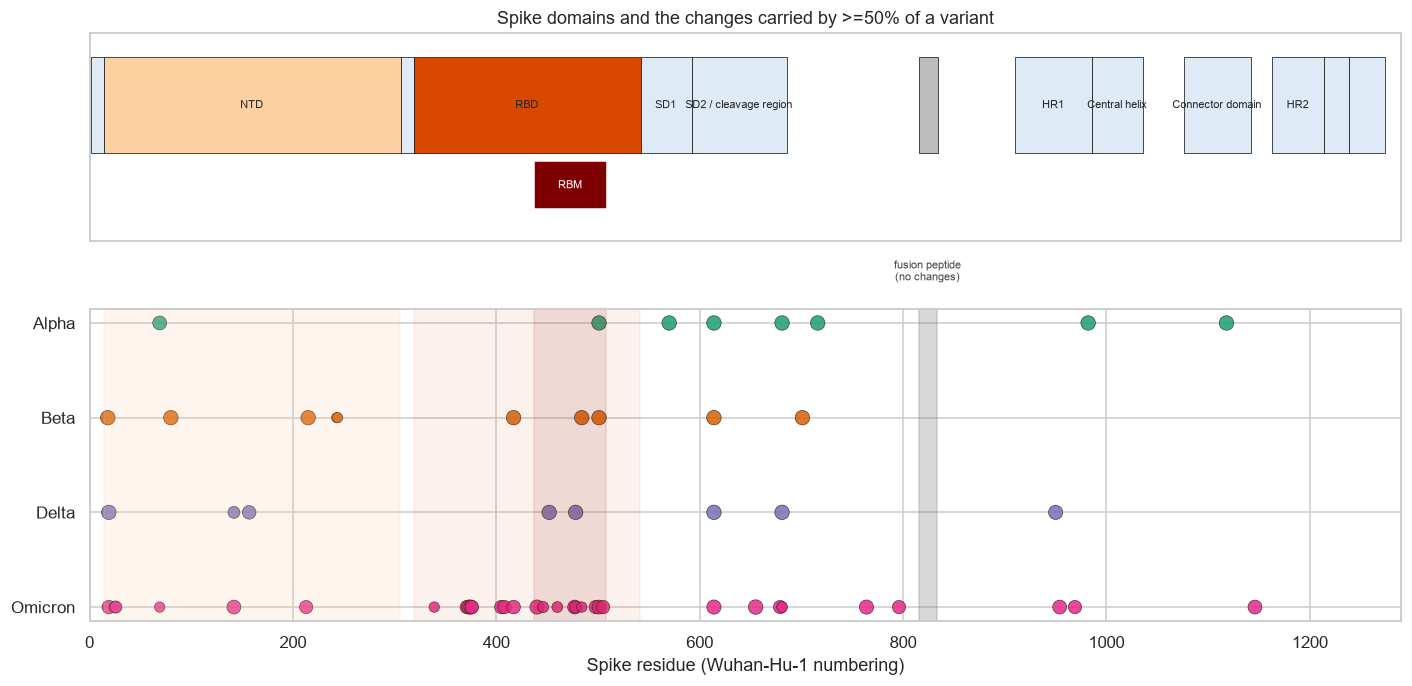

48 Spike changes reach >=50% in at least one variant


In [3]:
p = PCT["S"]
fig, ax = plt.subplots(2,1, figsize=(13,6.4), height_ratios=[1,1.5], sharex=True)
for name,a,b in DOMAINS["S"]:
    colour = "#d94801" if name=="RBD" else "#fdd0a2" if name=="NTD" else "#bdbdbd" if name=="Fusion peptide" else "#deebf7"
    ax[0].barh(0, b-a+1, left=a, height=.6, edgecolor="k", lw=.5, color=colour)
    if b-a > 45: ax[0].text((a+b)/2, 0, name, ha="center", va="center", fontsize=7)
ax[0].barh(-.5, RBM[1]-RBM[0]+1, left=RBM[0], height=.3, color="#7f0000")
ax[0].text((RBM[0]+RBM[1])/2, -.5, "RBM", ha="center", va="center", fontsize=7, color="w")
ax[0].set(ylim=(-.85,.45), yticks=[], title="Spike domains and the changes carried by >=50% of a variant")
ax[0].grid(False)

top = p[p[VARIANTS].max(axis=1) >= 50]
col = dict(zip(VARIANTS, ["#1b9e77","#d95f02","#7570b3","#e7298a"]))
for v in VARIANTS:
    sub = top[top[v] >= 50]
    ax[1].scatter(sub.codon, [v]*len(sub), s=sub[v]*.9, color=col[v], alpha=.85, edgecolor="k", lw=.4)
ax[1].axvspan(*RBM, color="#7f0000", alpha=.10)
ax[1].axvspan(319,541, color="#d94801", alpha=.07)
ax[1].axvspan(14,305, color="#fdd0a2", alpha=.18)
ax[1].axvspan(816,833, color="grey", alpha=.30)
ax[1].text(824, -.45, "fusion peptide\n(no changes)", ha="center", fontsize=7, color="#444")
ax[1].set(xlabel="Spike residue (Wuhan-Hu-1 numbering)", xlim=(0,1290)); ax[1].invert_yaxis()
plt.tight_layout(); plt.savefig(FIG_DIR/"fig7a_spike_domain_map.png", bbox_inches="tight"); plt.show()
print(f"{len(top)} Spike changes reach >=50% in at least one variant")

**Interpretation 6.2:**
The four variants place their changes differently. Alpha and Delta carry a single RBD change each (N501Y and L452R/T478K respectively) and spread the rest across the NTD, the cleavage region and HR1. Omicron instead fills the RBD: of its 48 changes above 50%, eleven fall inside the RBD and eight of those inside the RBM. The three positions the literature flags as convergent, 417, 484 and 501, are all occupied: K417N in Beta (100%) and Omicron (88%), position 484 in Beta as E484K (100%) and in Omicron as either E484A (52%) or E484K (44%), and N501Y in Alpha, Beta and Omicron (100%, 100%, 92%) but absent from Delta (0/25). Delta's substitution of L452R and T478K, both just outside the ACE2 contact surface, is a different solution to the same problem and matches the description in the literature of Delta as peripheral to the binding footprint.

### 6.3 Figure 7b: Nucleocapsid, structured against disordered
Stage 5 found that N is statistically as variable as Spike. If that variation fell inside the RNA-binding or dimerisation domains it would be difficult to reconcile with N's essential role, so the question for Stage 6 is where in the protein it sits.

Disordered regions : 29 changes / 164 aa = 17.68 per 100 aa
Folded domains     : 15 changes / 255 aa = 5.88 per 100 aa


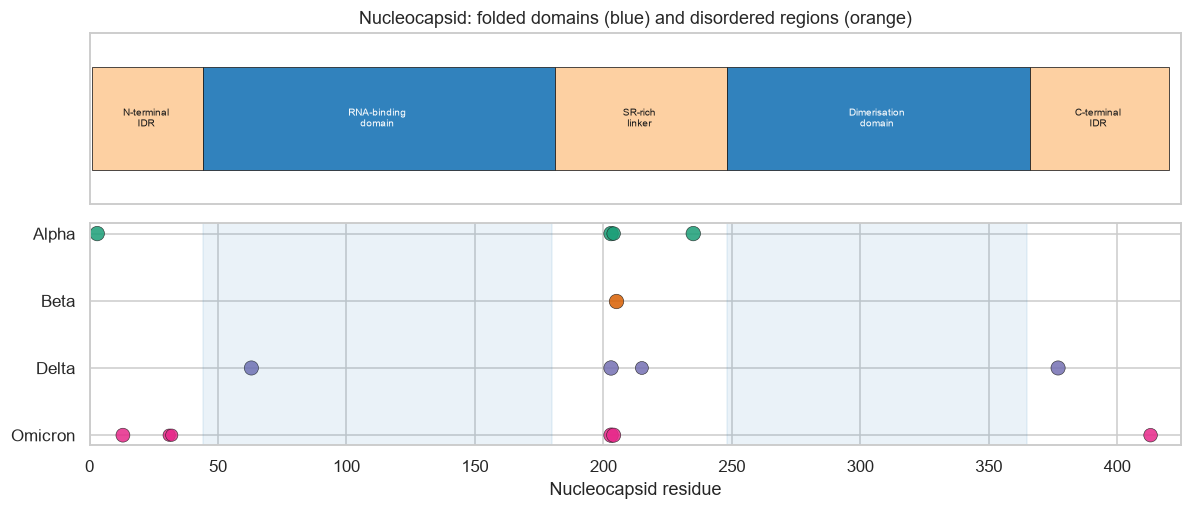

In [4]:
n = PCT["N"]
disordered = n[(n.codon<=43) | n.codon.between(181,247) | (n.codon>=366)]
structured = n[n.codon.between(44,180) | n.codon.between(248,365)]
dis_aa, str_aa = 43+67+54, 137+118
print(f"Disordered regions : {len(disordered):2d} changes / {dis_aa} aa = {len(disordered)/dis_aa*100:.2f} per 100 aa")
print(f"Folded domains     : {len(structured):2d} changes / {str_aa} aa = {len(structured)/str_aa*100:.2f} per 100 aa")

fig, ax = plt.subplots(2,1, figsize=(11,4.8), height_ratios=[1,1.3], sharex=True)
pal = {"N-terminal IDR":"#fdd0a2","SR-rich linker":"#fdd0a2","C-terminal IDR":"#fdd0a2",
       "RNA-binding domain":"#3182bd","Dimerisation domain":"#3182bd"}
for name,a,b in DOMAINS["N"]:
    ax[0].barh(0, b-a+1, left=a, height=.6, color=pal[name], edgecolor="k", lw=.5)
    ax[0].text((a+b)/2, 0, name.replace(" ","\n"), ha="center", va="center", fontsize=6.5,
               color="w" if pal[name]=="#3182bd" else "k")
ax[0].set(ylim=(-.5,.5), yticks=[], title="Nucleocapsid: folded domains (blue) and disordered regions (orange)")
ax[0].grid(False)
top_n = n[n[VARIANTS].max(axis=1) >= 50]
col = dict(zip(VARIANTS, ["#1b9e77","#d95f02","#7570b3","#e7298a"]))
for v in VARIANTS:
    sub = top_n[top_n[v] >= 50]
    ax[1].scatter(sub.codon, [v]*len(sub), s=sub[v]*.9, color=col[v], alpha=.85, edgecolor="k", lw=.4)
for a,b in [(44,180),(248,365)]: ax[1].axvspan(a,b, color="#3182bd", alpha=.10)
ax[1].set(xlabel="Nucleocapsid residue", xlim=(0,425)); ax[1].invert_yaxis()
plt.tight_layout(); plt.savefig(FIG_DIR/"fig7b_nucleocapsid_domains.png", bbox_inches="tight"); plt.show()

**Interpretation 6.3:**
The variation in N is concentrated in its disordered regions: 17.7 changes per 100 residues there against 5.9 in the two folded domains, a threefold difference. The densest single region is the serine/arginine-rich linker (19.4 per 100 aa), which holds R203K and G204R in Alpha and Omicron, R203M in Delta and T205I in Beta: four different substitutions at three adjacent positions in four independently arisen variants, which is a strong signal of convergent selection rather than drift. The RNA-binding domain (6.6) and the dimerisation domain (5.1) are comparatively quiet.

This resolves the apparent contradiction in the Stage 5 result. N is as variable as Spike when measured per kilobase, but the variation avoids the parts of the protein that fold and bind RNA. Describing N simply as "variable" would therefore be misleading; it is variable in its flexible linkers and conserved in its functional core.

### 6.4 RdRp: are the catalytic residues touched?
RdRp was the most conserved gene in Stage 5 (4.6 variable sites per kb). The strongest test of functional constraint is whether the catalytic residues themselves ever change: motif A aspartate D618, motif B residues S682 and N691, and the motif C SDD triad at 759-761, which coordinates the metal ions used in nucleotide addition.

                motif      residues  genomes_with_a_change changes_seen
       D618 (motif A)           618                      0         none
S682 / N691 (motif B)      682, 691                      0         none
SDD 759-761 (motif C) 759, 760, 761                      0         none

 kind  deletion  non-synonymous  synonymous  NS_per_synonymous
gene                                                         
E            0              34           1              34.00
M            0             119          40               2.98
N           36             321          17              18.88
RdRp         0             123         147               0.84
S          106            1394          80              17.42


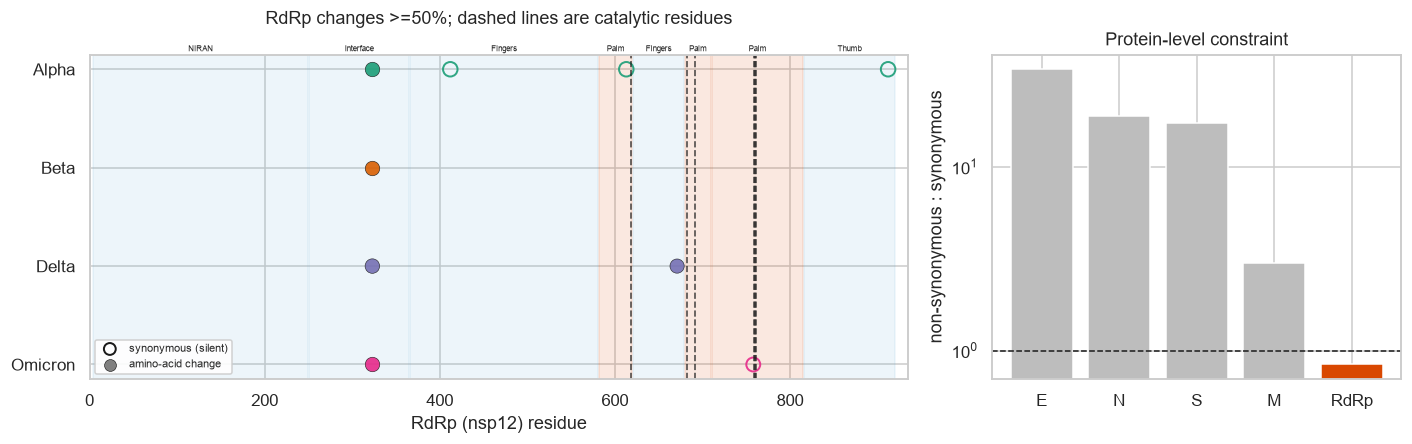

In [5]:
CATALYTIC = {"D618 (motif A)":[618], "S682 / N691 (motif B)":[682,691], "SDD 759-761 (motif C)":[759,760,761]}
r = changes[changes.gene=="RdRp"]
cat_rows=[]
for name,pos in CATALYTIC.items():
    hit = r[r.codon.isin(pos) & (r.kind!="synonymous")]
    cat_rows.append({"motif":name,"residues":", ".join(map(str,pos)),
                     "genomes_with_a_change":hit.strain.nunique(),
                     "changes_seen":", ".join(sorted(hit.label.unique())) or "none"})
cat = pd.DataFrame(cat_rows); cat.to_csv(RES_DIR/"stage6_rdrp_catalytic_check.csv", index=False)
print(cat.to_string(index=False))

kinds = pd.crosstab(changes.gene, changes.kind)
kinds["NS_per_synonymous"] = (kinds["non-synonymous"]/kinds["synonymous"].replace(0,np.nan)).round(2)
print("\n", kinds.to_string())

fig, ax = plt.subplots(1,2, figsize=(13,4.2), gridspec_kw={"width_ratios":[2,1]})
for name,a,b in DOMAINS["RdRp"]:
    ax[0].axvspan(a,b, alpha=.12, color="#d94801" if "motif" in name else "#6baed6")
    ax[0].text((a+b)/2, 1.01, name.split(" (")[0], ha="center", fontsize=5.5,
               transform=ax[0].get_xaxis_transform())

# separate silent changes from amino-acid changes: the point of this panel
syn = set(changes.loc[changes.kind=="synonymous","label"])
rp  = PCT["RdRp"]
for v in VARIANTS:
    sub = rp[rp[v] >= 50]
    for is_syn, mk, fc in [(True,"o","none"), (False,"o",None)]:
        s2 = sub[sub.label.isin(syn)] if is_syn else sub[~sub.label.isin(syn)]
        if not len(s2): continue
        ax[0].scatter(s2.codon, [v]*len(s2), s=s2[v]*.9,
                      facecolor=fc if is_syn else col[v], edgecolor=col[v] if is_syn else "k",
                      lw=1.3 if is_syn else .4, alpha=.9)
for pos in [618,682,691,759,760,761]:
    ax[0].axvline(pos, color="k", lw=1.1, ls="--", alpha=.75)
ax[0].scatter([],[], facecolor="none", edgecolor="k", lw=1.3, s=60, label="synonymous (silent)")
ax[0].scatter([],[], facecolor="grey", edgecolor="k", lw=.4, s=60, label="amino-acid change")
ax[0].legend(loc="lower left", fontsize=7, framealpha=.9)
ax[0].set(xlabel="RdRp (nsp12) residue", xlim=(0,935),
          title="")
ax[0].set_title("RdRp changes >=50%; dashed lines are catalytic residues", pad=20)
ax[0].invert_yaxis()

order = ["E","N","S","M","RdRp"]
ax[1].bar(order, [kinds.loc[g,"NS_per_synonymous"] for g in order], color=["#bdbdbd"]*4+["#d94801"])
ax[1].axhline(1, color="k", ls="--", lw=1)
ax[1].set(ylabel="non-synonymous : synonymous", title="Protein-level constraint", yscale="log")
plt.tight_layout(); plt.savefig(FIG_DIR/"fig7c_rdrp_and_constraint.png", bbox_inches="tight"); plt.show()


**Interpretation 6.4:**
No genome in the sample carries a change at any catalytic residue. D618, S682, N691 and the SDD triad at 759-761 are identical to Wuhan-Hu-1 in all 79 genomes across all four variants. The only RdRp change that is fixed everywhere is P323L, which sits in the interface subdomain roughly 440 residues away from the catalytic centre and is a marker of the clade that spread in early 2020 rather than an adaptation of the enzyme.

The counts of change types point the same way. RdRp is the only gene in the study where synonymous changes outnumber amino-acid changes (147 against 123, a ratio of 0.84). Every other gene is heavily skewed the other way: E 34.0, N 18.9, S 17.4 and M 3.0. A ratio below one is what purifying selection on a protein sequence looks like, since changes that do not alter the protein are tolerated while those that do are removed. This is a count ratio over a small sample and not a formal dN/dS test, but the contrast between RdRp and the other four genes is large and consistent with the structural result above.

### 6.5 Comparison with the published literature
Each row states a finding from this study, the published claim it is being compared with, and whether the two agree.

In [6]:
lit = pd.DataFrame([
 ("Spike is the most variable gene (34.5 variable sites/kb; 132 sites)",
  "Spike holds ~50% of mutations while being ~17% of the genome, across the whole genus",
  "LaTourrette et al. (2021)","Agrees"),
 ("RdRp is the most conserved gene (4.6 sites/kb; 98.6% invariant)",
  "ORF1b replication proteins are the least variable region of the genus",
  "LaTourrette et al. (2021)","Agrees"),
 ("N is statistically as variable as Spike (median 5.56 vs 4.19/kb, p=0.27)",
  "The fastest-evolving region of the genome lies within the nucleocapsid gene",
  "Jungreis et al. (2021)","Agrees"),
 ("N variation is 3x denser in disordered regions than folded domains (17.7 vs 5.9/100 aa)",
  "Not addressed by the reviewed literature",
  "This study","Extends"),
 ("R203K/G204R in the SR-rich linker: Alpha 100%/88%, Omicron 100%/96%",
  "R203K/G204R are adaptive, raise replication and infectivity, and rose with Alpha",
  "Wu et al. (2021)","Agrees"),
 ("RBD is enriched for variable sites (6.9% vs 2.7% of the rest of Spike, OR 2.6)",
  "Spike's RBD concentrates the substitutions that matter for antigenicity",
  "Harvey et al. (2021)","Agrees"),
 ("Positions 417, 484 and 501 are occupied in Beta and Omicron; 501 also in Alpha",
  "K417N/T, E484K/A and N501Y recur across independently arisen variants",
  "Dejnirattisai et al. (2022)","Agrees"),
 ("Delta carries L452R and T478K and no change at 417, 484 or 501",
  "Delta's RBD changes are peripheral to the ACE2 binding footprint",
  "Dejnirattisai et al. (2022)","Agrees"),
 ("7 of the 9 published Omicron RBD changes exceed 50%; Q493R 24%, G496S 4%",
  "Omicron's RBD carries K417N, G446S, S477N, E484A, Q493R, G496S, Q498R, N501Y, Y505H",
  "Dejnirattisai et al. (2022)","Partly - see 6.5 note"),
 ("No change at any RdRp catalytic residue; P323L fixed in 100% of genomes",
  "P323L travelled with D614G and marks clade G; it lies away from the active site",
  "Mercatelli & Giorgi (2020)","Agrees"),
 ("D614G in 96-100% of genomes of every variant",
  "D614G became globally dominant and underlies all variants of concern",
  "Winger & Caspari (2021)","Agrees"),
 ("E most conserved structural protein by median divergence (0.00/kb), M next (1.49)",
  "M had the fewest amino-acid changes per residue of the four structural proteins",
  "Troyano-Hernaez et al. (2021)","Differs - see 6.5 note"),
], columns=["Finding in this study","Published claim","Source","Agreement"])
lit.to_csv(RES_DIR/"stage6_literature_comparison.csv", index=False)
print(lit.to_string(index=False, max_colwidth=58))

                                     Finding in this study                                            Published claim                        Source              Agreement
Spike is the most variable gene (34.5 variable sites/kb... Spike holds ~50% of mutations while being ~17% of the g...     LaTourrette et al. (2021)                 Agrees
RdRp is the most conserved gene (4.6 sites/kb; 98.6% in... ORF1b replication proteins are the least variable regio...     LaTourrette et al. (2021)                 Agrees
N is statistically as variable as Spike (median 5.56 vs... The fastest-evolving region of the genome lies within t...        Jungreis et al. (2021)                 Agrees
N variation is 3x denser in disordered regions than fol...                   Not addressed by the reviewed literature                    This study                Extends
R203K/G204R in the SR-rich linker: Alpha 100%/88%, Omic... R203K/G204R are adaptive, raise replication and infecti...              Wu et al. (202

**Interpretation 6.5:**
Ten of the twelve comparisons agree with the published work, which is the main evidence that the pipeline behaves correctly. Two need comment.

**The Omicron RBD set.** Seven of the nine changes reported by Dejnirattisai et al. (2022) exceed 50% in our Omicron genomes, but Q493R reaches only 24% and G496S only 4%. This is not a contradiction. The Stage 5 sample deliberately draws 25 *different* Omicron lineages, whereas the published set describes the original BA.1 lineage; Q493R reverted and G496S was lost in BA.2 and the lineages that followed. Our sample also contains later RBD changes absent from BA.1, including R346T, L455S, F456L and F486P, each in 20-44% of genomes. The disagreement is therefore a property of lineage sampling, not of the method, and it argues for reporting Omicron by lineage rather than as one group.

**Which structural protein is most conserved.** Troyano-Hernaez et al. (2021) found M the most conserved of the four structural proteins per residue, whereas here E has the lowest median divergence (0.00 per kb against 1.49 for M), although the two are almost tied on variable sites per kb (17.5 against 17.9). Two differences explain this. Their dataset ends in September 2020, before Alpha, Delta and Omicron, and E is only 228 nt long, so with four variable sites a single genome moves its rate substantially. The bootstrap intervals in Stage 5 separate E from M for nucleotide diversity but overlap for mean divergence, so this study cannot rank E against M with confidence, exactly as the literature review predicted.

### 6.6 Summary and hand-off

1. **Spike varies where antibodies bind and nowhere else of consequence.** The RBM carries 54.2 changes per 100 residues; the fusion peptide and the NTD-RBD linker carry none.
2. **Nucleocapsid is variable in its disordered linkers, not its folded core** (17.7 against 5.9 per 100 aa). This explains how N can be statistically as variable as Spike while remaining functionally constrained, and it is the finding that the original hypothesis did not anticipate.
3. **RdRp is conserved exactly where it matters.** No change at any catalytic residue in 79 genomes, and the only gene in the study where synonymous changes outnumber amino-acid changes.
4. **The convergent positions predicted by the literature are all occupied**, and the two points of disagreement are explained by lineage sampling and by the small size of the E gene.

**For Stage 8 (conclusions):** the hypothesis is supported for RdRp and M against Spike, cannot be settled for E, and is silent on N, which this notebook shows is variable in a specific and biologically coherent way. The supplementary prediction added at the literature-review stage, that N would approach Spike once normalised by gene length, is supported.

**For Stage 7 (machine learning):** the classifier's most informative features should fall in the RBD and NTD of Spike and in the SR-rich linker of N. If feature importance instead spreads evenly along the genes, that is a sign of near-duplicate leakage rather than a biological signal.